# **Uji Hyperparameter: Random Search dengan KerasTuner**

Notebook 03 dan 04 menentukan hyperparameter lewat pencarian bertahap. Kelemahan pendekatan ini adalah interaksi antar-hyperparameter tidak semuanya teruji, dan nilai yang dicoba terbatas pada beberapa pilihan tetap. Notebook ini menguji ulang hasil tersebut dengan **Random Search** dari **KerasTuner**. Pencarian dilakukan di ruang hyperparameter yang lebih luas, dan semua hyperparameter diacak **bersamaan**, sehingga kombinasi yang belum pernah dicoba di eksperimen bertahap ikut teruji.

**Aturan keputusan:**
1. Tiga konfigurasi terbaik dari Random Search dilatih ulang dengan 3 seed yang sama seperti sebelumnya (42, 123, 2026), dan dinilai dengan PR-AUC validation (*average precision*, scikit-learn).
2. Kandidat terbaik adalah kandidat dengan rata-rata PR-AUC tertinggi.
3. Model **hanya diganti** kalau hasilnya **lebih baik secara jelas**, yaitu rata-rata konfigurasi sekarang berada **di bawah batas setara** kandidat (rata-rata kandidat dikurangi 1 standar deviasi kandidat). Definisi batas setara ini sama dengan aturan di notebook 03 dan 04.
4. Kalau tidak lebih baik secara jelas, konfigurasi sekarang dipertahankan dan hasil notebook ini dilaporkan sebagai bukti bahwa konfigurasi tersebut sudah optimal di ruang pencarian yang diuji.

Seperti notebook sebelumnya, semua penilaian dilakukan di data validation dan **data test tidak disentuh**.

**Penanggung jawab:** Wilbert Edric Tanjiro (231110595)

## **1. Import Library dan Konfigurasi**

Random Search berisi 30 trial, ditambah 9 run untuk konfirmasi 3 seed. Prosesnya sekitar 45 sampai 75 menit di CPU. Kalau `RUN_EXPERIMENTS = False`, hasil yang tersimpan di `reports/results/` dimuat tanpa training ulang.

KerasTuner dengan backend TensorFlow membutuhkan paket `tensorboard` walaupun TensorBoard tidak dipakai. Kedua paket sudah ditambahkan ke `requirements.txt`.

In [5]:
import sys
import json
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import keras_tuner as kt

from src import config
from src import preprocessing as prep
from src import model as M
from src import visualization as viz

RUN_EXPERIMENTS = False
MAX_TRIALS = 30
TUNER_DIR = config.MODELS_DIR / "tmp" / "kerastuner"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
viz.set_style()
print("TensorFlow :", tf.__version__, "| Keras:", keras.__version__, "| KerasTuner:", kt.__version__)
print("RUN_EXPERIMENTS :", RUN_EXPERIMENTS)

TensorFlow : 2.21.0 | Keras: 3.15.1 | KerasTuner: 1.4.8
RUN_EXPERIMENTS : False


## **2. Konfigurasi Sekarang sebagai Pembanding**

Konfigurasi sekarang adalah hasil notebook 04. Hasil 3 seed-nya diambil dari `04_eksperimen_runs.csv`, jadi tidak ada training ulang untuk pembanding ini.

In [6]:
data = prep.prepare_datasets()
assert data["test_fingerprint"] == prep.load_preprocessing_config()["split"]["test_fingerprint"]

konfig_04 = M.load_json(config.RESULTS_DIR / "04_konfigurasi_final.json")
cfg_sekarang = konfig_04["konfigurasi"]
runs_04 = pd.read_csv(config.RESULTS_DIR / "04_eksperimen_runs.csv")
hist_04 = M.load_json(config.RESULTS_DIR / "04_riwayat_training.json")
runs_sekarang = runs_04[runs_04["skenario"] == konfig_04["skenario_e5"]].copy()
runs_sekarang["skenario"] = "sekarang"

mean_sekarang = runs_sekarang["val_pr_auc"].mean()
std_sekarang = runs_sekarang["val_pr_auc"].std(ddof=1)
keras_sekarang = [max(hist_04[f"{konfig_04['skenario_e5']}|{s}"]["val_pr_auc"]) for s in M.SEEDS]

print("Konfigurasi sekarang :", M.config_label(cfg_sekarang), "| lr", cfg_sekarang["learning_rate"], "| batch", cfg_sekarang["batch_size"])
print(f"PR-AUC validation (sklearn, 3 seed): {mean_sekarang:.4f} +- {std_sekarang:.4f}")
print(f"PR-AUC validation (metrik Keras, epoch terbaik): {np.mean(keras_sekarang):.4f} +- {np.std(keras_sekarang, ddof=1):.4f}")

Konfigurasi sekarang : [128-64] do=0.2 | lr 0.001 | batch 512
PR-AUC validation (sklearn, 3 seed): 0.4468 +- 0.0015
PR-AUC validation (metrik Keras, epoch terbaik): 0.4467 +- 0.0015


## **3. Ruang Pencarian**

Ruang pencarian dibuat **lebih luas** daripada eksperimen bertahap, supaya Random Search punya kesempatan menemukan kombinasi yang belum pernah dicoba. Aktivasi ReLU, optimizer Adam, dan loss BCE tetap dikunci sesuai keputusan kelompok dan hasil notebook 05.

| Hyperparameter | Eksperimen bertahap (03 dan 04) | Random Search |
|---|---|---|
| Jumlah hidden layer | 2 atau 3 | 1 sampai 4 |
| Neuron layer pertama | 64, 128, 256 | 32, 64, 128, 256, 512 (layer berikutnya dibagi dua, minimal 16) |
| Dropout | 0, 0,2, 0,3 | 0 sampai 0,5 (kelipatan 0,05) |
| L2 | 0, 1e-5, 1e-4 | 0, 1e-6, 1e-5, 1e-4, 1e-3 |
| BatchNorm | ada atau tidak | ada atau tidak |
| Learning rate | 0,0003, 0,001, 0,003 | 0,0001 sampai 0,01 (skala log, kontinu) |
| Batch size | 256, 512, 1024 | 256, 512, 1024 |

Protokol setiap trial sama dengan eksperimen sebelumnya, yaitu `tf.data` dengan seed 42, maksimal 100 epoch, dan EarlyStopping dengan patience 8 pada PR-AUC validation. Objektif KerasTuner adalah `val_pr_auc` dari metrik Keras. Metrik ini sedikit berbeda dengan *average precision* scikit-learn karena memakai pendekatan 200 titik threshold. Karena itu, keputusan akhir tetap memakai average precision dari hasil konfirmasi 3 seed.

In [7]:
def hidden_dari_hp(n_layers, units_1):
    return [max(units_1 // (2 ** i), 16) for i in range(n_layers)]

def cfg_dari_hp(v):
    return {"hidden_units": hidden_dari_hp(int(v["n_layers"]), int(v["units_1"])),
            "dropout": round(float(v["dropout"]), 2), "l2": float(v["l2"]), "batch_norm": bool(v["batch_norm"]),
            "learning_rate": float(v["learning_rate"]), "batch_size": int(v["batch_size"])}

class MLPHyperModel(kt.HyperModel):
    def build(self, hp):
        M.set_seed(config.SEED)
        n_layers = hp.Int("n_layers", 1, 4)
        units_1 = hp.Choice("units_1", [32, 64, 128, 256, 512])
        return M.build_model(
            hidden_units=hidden_dari_hp(n_layers, units_1),
            dropout=hp.Float("dropout", 0.0, 0.5, step=0.05),
            l2=hp.Choice("l2", [0.0, 1e-6, 1e-5, 1e-4, 1e-3]),
            batch_norm=hp.Boolean("batch_norm"),
            learning_rate=hp.Float("learning_rate", 1e-4, 1e-2, sampling="log"),
        )

    def fit(self, hp, model, *args, **kwargs):
        bs = hp.Choice("batch_size", [256, 512, 1024])
        train_ds = M.make_dataset(data["X_train"], data["y_train"], bs, shuffle=True, seed=config.SEED)
        val_ds = M.make_dataset(data["X_val"], data["y_val"], M.EVAL_BATCH)
        return model.fit(train_ds, validation_data=val_ds, shuffle=False, **kwargs)

tuner = kt.RandomSearch(
    MLPHyperModel(),
    objective=kt.Objective("val_pr_auc", direction="max"),
    max_trials=MAX_TRIALS,
    seed=config.SEED,
    directory=str(TUNER_DIR),
    project_name="random_search_mlp",
    overwrite=RUN_EXPERIMENTS,
)
tuner.search_space_summary()

Search space summary
Default search space size: 6
n_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 4, 'step': 1, 'sampling': 'linear'}
units_1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128, 256, 512], 'ordered': True}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.05, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 1e-06, 1e-05, 0.0001, 0.001], 'ordered': True}
batch_norm (Boolean)
{'default': False, 'conditions': []}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.01, 'step': None, 'sampling': 'log'}


## **4. Menjalankan Random Search**

In [8]:
TRIALS_PATH = config.RESULTS_DIR / "04b_random_search_trials.csv"

if RUN_EXPERIMENTS:
    t0 = time.time()
    tuner.search(epochs=M.MAX_EPOCHS, verbose=0, callbacks=[
        keras.callbacks.EarlyStopping(monitor=M.MONITOR, mode="max", patience=M.PATIENCE, restore_best_weights=True)])
    durasi_search = (time.time() - t0) / 60
    baris = []
    for tr in tuner.oracle.get_best_trials(MAX_TRIALS):
        v = tr.hyperparameters.values
        cfg = cfg_dari_hp(v)
        baris.append({"trial": tr.trial_id, **{k: v[k] for k in ["n_layers", "units_1", "dropout", "l2", "batch_norm",
                                                                  "learning_rate", "batch_size"]},
                      "hidden_units": "-".join(map(str, cfg["hidden_units"])),
                      "params": int(M.build_model(**cfg).count_params()),
                      "val_pr_auc_keras": float(tr.score)})
        keras.backend.clear_session()
    trials = pd.DataFrame(baris).sort_values("val_pr_auc_keras", ascending=False).reset_index(drop=True)
    trials["dropout"] = trials["dropout"].round(2)
    trials.to_csv(TRIALS_PATH, index=False)
    print(f"Random Search selesai: {len(trials)} trial dalam {durasi_search:.1f} menit")
else:
    trials = pd.read_csv(TRIALS_PATH)
    print(f"Memuat {len(trials)} trial dari {TRIALS_PATH.relative_to(ROOT)}")

display(trials.round({"learning_rate": 5, "val_pr_auc_keras": 4}))

Memuat 30 trial dari reports\results\04b_random_search_trials.csv


,trial,n_layers,units_1,dropout,l2,batch_norm,learning_rate,batch_size,hidden_units,params,val_pr_auc_keras
0,13,2,128,0.20,0.000100,True,0.00014,256,128-64,11713,0.4477
1,27,3,512,0.10,0.000100,False,0.00049,1024,512-256-128,175617,0.4475
2,10,4,128,0.00,0.000001,True,0.00439,256,128-64-32-16,14417,0.4473
3,6,2,256,0.05,0.000100,False,0.00062,256,256-128,38657,0.4473
4,11,3,512,0.25,0.000000,True,0.00013,1024,512-256-128,178305,0.4473
5,17,1,128,0.00,0.000010,False,0.00011,256,128,2945,0.4469
6,21,4,128,0.00,0.000100,False,0.00133,1024,128-64-32-16,13697,0.4469
7,22,3,256,0.25,0.000000,False,0.00012,256,256-128-64,46849,0.4468
8,25,4,512,0.15,0.000100,True,0.00031,1024,512-256-128-64,186689,0.4468
9,9,4,512,0.35,0.000001,False,0.00036,1024,512-256-128-64,183809,0.4465


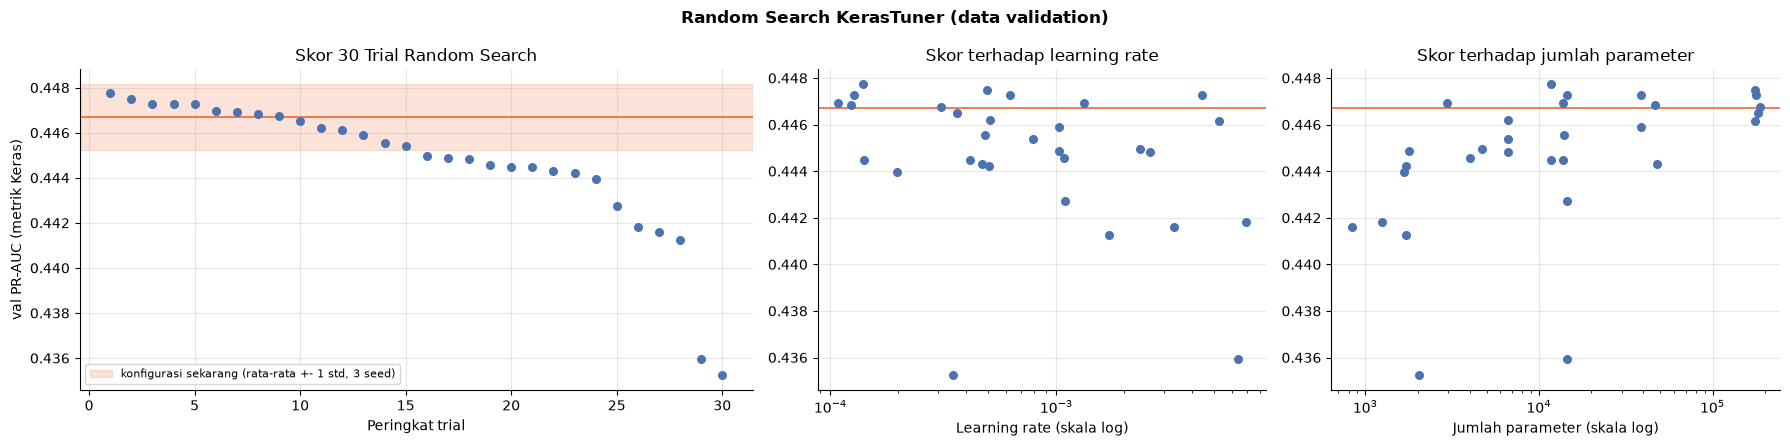

Rentang skor trial: 0.4352 sampai 0.4477
Trial dengan skor di atas rata-rata konfigurasi sekarang (0.4467): 9
Trial di atas batas atas pita konfigurasi sekarang (0.4482): 0


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1.5, 1, 1]})
m_k, s_k = np.mean(keras_sekarang), np.std(keras_sekarang, ddof=1)

ax = axes[0]
ax.scatter(range(1, len(trials) + 1), trials["val_pr_auc_keras"], color=viz.WARNA_VAL, s=30, zorder=3)
ax.axhspan(m_k - s_k, m_k + s_k, color="#eb6834", alpha=0.18, label="konfigurasi sekarang (rata-rata +- 1 std, 3 seed)")
ax.axhline(m_k, color="#eb6834", lw=1.2)
ax.set_xlabel("Peringkat trial")
ax.set_ylabel("val PR-AUC (metrik Keras)")
ax.set_title("Skor 30 Trial Random Search")
ax.legend(fontsize=8, loc="lower left")

for ax, kol, judul in [(axes[1], "learning_rate", "Learning rate"), (axes[2], "params", "Jumlah parameter")]:
    ax.scatter(trials[kol], trials["val_pr_auc_keras"], color=viz.WARNA_VAL, s=30, zorder=3)
    ax.axhline(m_k, color="#eb6834", lw=1.2)
    ax.set_xscale("log")
    ax.set_xlabel(f"{judul} (skala log)")
    ax.set_title(f"Skor terhadap {judul.lower()}")
fig.suptitle("Random Search KerasTuner (data validation)", fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "rs_01_trial_random_search")
plt.show()

print(f"Rentang skor trial: {trials['val_pr_auc_keras'].min():.4f} sampai {trials['val_pr_auc_keras'].max():.4f}")
print(f"Trial dengan skor di atas rata-rata konfigurasi sekarang ({m_k:.4f}): {(trials['val_pr_auc_keras'] > m_k).sum()}")
print(f"Trial di atas batas atas pita konfigurasi sekarang ({m_k + s_k:.4f}): {(trials['val_pr_auc_keras'] > m_k + s_k).sum()}")

**Interpretasi:** Random Search menyelesaikan 30 trial dalam 39,7 menit. Skor val PR-AUC (metrik Keras) berada di rentang 0,4352 sampai 0,4477. Ada 9 trial yang skornya di atas rata-rata konfigurasi sekarang (0,4467), tetapi **tidak ada satu pun** yang melewati batas atas pita variasi seed konfigurasi sekarang (0,4482). Dari skor satu kali training saja, belum ada trial yang jelas lebih baik.

Pola dari ke-30 trial:

- **Model yang sangat kecil lebih buruk.** Enam trial dengan parameter di bawah 2.000 rata-ratanya 0,4430, sedangkan kelompok 10 ribu sampai 50 ribu parameter rata-ratanya 0,4450. Model yang lebih besar dari 50 ribu parameter tidak memberi skor tertinggi yang lebih baik (maksimum 0,4475).
- **Regularisasi yang terlalu kuat merugikan.** Keempat trial dengan L2 1e-3 semuanya berada di paruh bawah peringkat (0,4359 sampai 0,4443). Trial paling buruk (0,4352) adalah model kecil dengan dropout 0,45.
- **BatchNorm tidak selalu membantu.** Rata-rata trial dengan BatchNorm (0,4438) justru lebih rendah dibanding tanpa BatchNorm (0,4457), walaupun skor tertingginya mirip. Efek BatchNorm bergantung pada kombinasi hyperparameter lainnya.
- **Learning rate** tidak menunjukkan pola tunggal yang jelas. Skor yang baik muncul di rentang 0,0001 sampai 0,0045.

Tiga trial teratas memiliki skor yang sangat berdekatan (0,4473 sampai 0,4477) dengan arsitektur yang berbeda-beda. Ini sejalan dengan temuan notebook 03 dan 04 bahwa banyak konfigurasi berbeda menghasilkan performa yang hampir sama.

## **5. Konfirmasi 3 Seed untuk Tiga Kandidat Teratas**

Skor setiap trial berasal dari satu kali training. Pemenang Random Search bisa saja unggul hanya karena kebetulan seed, apalagi kalau trial-nya banyak. Karena itu, tiga kandidat teratas dilatih ulang dengan protokol yang sama persis seperti notebook 03 dan 04, yaitu `M.train_one()` dengan 3 seed, lalu dinilai dengan average precision scikit-learn.

In [10]:
KONF_PATH = config.RESULTS_DIR / "04b_konfirmasi_3seed.csv"
KONF_HIST = config.RESULTS_DIR / "04b_riwayat_konfirmasi.json"
kandidat = {f"kandidat_{i + 1}": cfg_dari_hp(trials.iloc[i]) for i in range(3)}
for nama, cfg in kandidat.items():
    print(f"{nama}: {M.config_label(cfg)} | params {M.build_model(**cfg).count_params():,}")

if RUN_EXPERIMENTS:
    t0 = time.time()
    runs_kand, hist_kand = M.run_configs(kandidat, data, prefix="RS")
    runs_kand.to_csv(KONF_PATH, index=False)
    M.save_json(hist_kand, KONF_HIST)
    print(f"\nKonfirmasi selesai dalam {(time.time() - t0) / 60:.1f} menit")
else:
    runs_kand = pd.read_csv(KONF_PATH)
    print(f"\nMemuat {len(runs_kand)} run dari {KONF_PATH.relative_to(ROOT)}")

kandidat_1: [128-64] do=0.2 l2=0.0001 BN lr=0.000139551 bs=256 | params 11,713
kandidat_2: [512-256-128] do=0.1 l2=0.0001 lr=0.000493897 bs=1024 | params 175,617
kandidat_3: [128-64-32-16] do=0.0 l2=1e-06 BN lr=0.00439253 bs=256 | params 14,417

Memuat 9 run dari reports\results\04b_konfirmasi_3seed.csv


In [11]:
runs_banding = pd.concat([runs_sekarang.drop(columns=["tahap"]), runs_kand], ignore_index=True)
ringkas = M.summarize(runs_banding)
display(ringkas[["config", "params", "val_pr_auc_mean", "val_pr_auc_std", "val_roc_auc_mean",
                 "train_pr_auc_mean", "gap_pr_auc_mean", "best_epoch_mean", "seconds_mean"]].round(4))

ringkas_kand = ringkas.drop(index="sekarang")
terbaik = ringkas_kand["val_pr_auc_mean"].idxmax()
mean_kand = ringkas_kand.loc[terbaik, "val_pr_auc_mean"]
std_kand = ringkas_kand.loc[terbaik, "val_pr_auc_std"]
batas = mean_kand - std_kand
GANTI = bool(mean_sekarang < batas)

print(f"Kandidat terbaik       : {terbaik} -> {ringkas_kand.loc[terbaik, 'config']}")
print(f"Rata-rata kandidat     : {mean_kand:.4f} +- {std_kand:.4f}")
print(f"Batas setara kandidat  : {batas:.4f}")
print(f"Rata-rata sekarang     : {mean_sekarang:.4f}")
print(f"Selisih (kandidat - sekarang): {mean_kand - mean_sekarang:+.4f}")
print("KEPUTUSAN:", "GANTI konfigurasi" if GANTI else "PERTAHANKAN konfigurasi sekarang")

,config,params,val_pr_auc_mean,val_pr_auc_std,val_roc_auc_mean,train_pr_auc_mean,gap_pr_auc_mean,best_epoch_mean,seconds_mean
skenario,,,,,,,,,
sekarang,[128-64] do=0.2,11137,0.4468,0.0015,0.8187,0.4498,0.0030,18.3333,65.7667
kandidat_1,[128-64] do=0.2 l2=0.0001 BN lr=0.000139551 bs...,11713,0.4472,0.0011,0.8196,0.4429,-0.0043,40.6667,116.5667
kandidat_2,[512-256-128] do=0.1 l2=0.0001 lr=0.000493897 ...,175617,0.4474,0.0003,0.8195,0.4448,-0.0026,14.6667,76.3333
kandidat_3,[128-64-32-16] do=0.0 l2=1e-06 BN lr=0.0043925...,14417,0.4479,0.0006,0.8188,0.4468,-0.0011,8.0000,37.3333


Kandidat terbaik       : kandidat_3 -> [128-64-32-16] do=0.0 l2=1e-06 BN lr=0.00439253 bs=256
Rata-rata kandidat     : 0.4479 +- 0.0006
Batas setara kandidat  : 0.4472
Rata-rata sekarang     : 0.4468
Selisih (kandidat - sekarang): +0.0011
KEPUTUSAN: GANTI konfigurasi


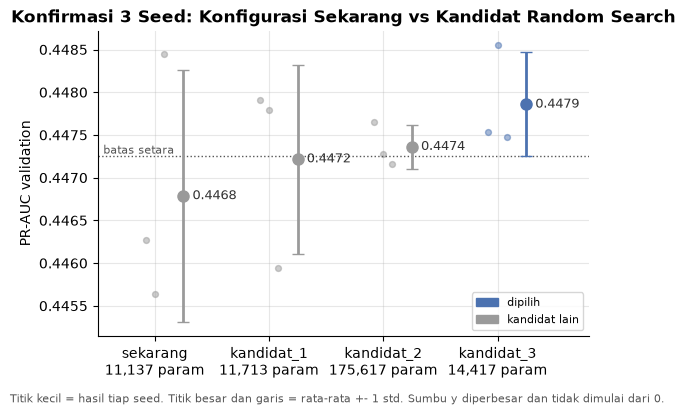

In [12]:
pilih_plot = terbaik if GANTI else "sekarang"
urut = ["sekarang"] + list(kandidat)
viz.plot_tahap(runs_banding, ringkas.loc[urut].assign(setara_dengan_terbaik=True), pilih_plot,
               "Konfirmasi 3 Seed: Konfigurasi Sekarang vs Kandidat Random Search", "rs_02_konfirmasi_3seed",
               label_x={s: (f"{s}\n{ringkas.loc[s, 'params']:,} param") for s in urut})

**Interpretasi:** Setelah dilatih ulang dengan 3 seed dan dinilai dengan average precision scikit-learn, hasilnya:

| Konfigurasi | Parameter | PR-AUC (3 seed) | Epoch terbaik |
|---|---|---|---|
| Sekarang: [128-64], dropout 0,2, lr 0,001, batch 512 | 11.137 | 0,4468 +- 0,0015 | 18,3 |
| Kandidat 1: [128-64], BatchNorm, L2 1e-4, lr 0,00014, batch 256 | 11.713 | 0,4472 +- 0,0011 | 40,7 |
| Kandidat 2: [512-256-128], dropout 0,1, L2 1e-4, lr 0,00049, batch 1024 | 175.617 | 0,4474 +- 0,0003 | 14,7 |
| **Kandidat 3: [128-64-32-16], tanpa dropout, BatchNorm, L2 1e-6, lr 0,0044, batch 256** | **14.417** | **0,4479 +- 0,0006** | **8,0** |

Kandidat 3 punya rata-rata tertinggi. Batas setaranya adalah 0,4479 - 0,0006 = **0,4473**, dan rata-rata konfigurasi sekarang (0,4468) berada **di bawah** batas tersebut. Sesuai aturan yang ditetapkan sebelum pencarian, **konfigurasi diganti** dengan kandidat 3.

Keputusan ini perlu dibaca dengan tiga catatan:
1. Selisihnya sangat kecil, hanya +0,0011 PR-AUC (sekitar 0,25%). Secara praktis kedua konfigurasi hampir sama, dan ROC-AUC rata-ratanya bahkan setara (0,8188 berbanding 0,8187).
2. Standar deviasi dari 3 seed masih berupa perkiraan kasar. Std kandidat 3 yang kecil (0,0006) membuat batasnya ketat sehingga lebih mudah dilewati.
3. Kandidat dipilih dari 30 trial dan dinilai di data validation yang sama, jadi hasilnya cenderung sedikit optimis. Penilaian yang tidak bias hanya bisa didapat dari data test di notebook 07.

Keputusan tetap mengikuti aturan, karena aturan sengaja ditetapkan sebelum melihat hasil. Mengubah aturan setelah hasil keluar justru membuat pemilihan model bisa diarahkan sesuai keinginan.

## **6. Model Tanpa Fitur Unik dengan Konfigurasi Hasil Keputusan**

Bagian ini menjalankan konsekuensi dari aturan keputusan. Kalau konfigurasi diganti, model tanpa fitur unik dilatih ulang dengan konfigurasi baru memakai seed 42 dan callback yang sama (EarlyStopping dan ModelCheckpoint pada PR-AUC validation). Model disimpan ke `models/mlp_tanpa_fitur_unik_rs.keras`, dan konfigurasinya ke `reports/results/04b_konfigurasi_final.json`. Notebook 05 membaca keputusan ini untuk menentukan konfigurasi dasar fitur unik pertama. Model dan file dari notebook 04 tetap disimpan sebagai dokumentasi tahap bertahap.

Kalau konfigurasi tidak diganti, tidak ada model baru yang dilatih.

Konfigurasi baru : [128-64-32-16] do=0.0 l2=1e-06 BN lr=0.00439253 bs=256
Epoch dijalankan : 15 (terbaik di epoch 7)
PR-AUC validation: 0.447537 | konfirmasi seed 42: 0.447537 | identik: True
ROC-AUC validation: 0.8184
Model tersimpan  : models\mlp_tanpa_fitur_unik_rs.keras (233.1 KB)


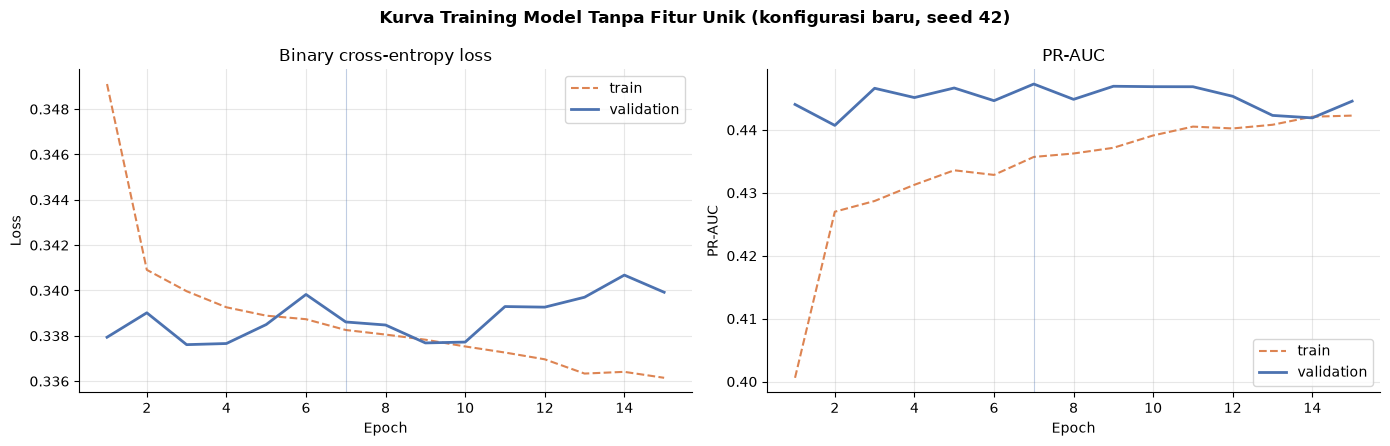

In [13]:
FINAL_RS_PATH = config.MODELS_DIR / "mlp_tanpa_fitur_unik_rs.keras"
FINAL_RS_HIST = config.RESULTS_DIR / "04b_riwayat_model_final.json"

if GANTI:
    cfg_final = kandidat[terbaik]
    if RUN_EXPERIMENTS:
        model_rs, ringkasan_rs, hist_rs = M.train_one(cfg_final, data, seed=42, run_name="final_rs")
        model_rs.save(FINAL_RS_PATH)
        M.save_json({"ringkasan": ringkasan_rs, "history": hist_rs}, FINAL_RS_HIST)
    else:
        model_rs = keras.models.load_model(FINAL_RS_PATH)
        tersimpan = M.load_json(FINAL_RS_HIST)
        ringkasan_rs, hist_rs = tersimpan["ringkasan"], tersimpan["history"]

    konf_seed42 = runs_kand[(runs_kand["skenario"] == terbaik) & (runs_kand["seed"] == 42)].iloc[0]
    prob_rs = model_rs.predict(data["X_val"], batch_size=M.EVAL_BATCH, verbose=0).ravel()
    from sklearn.metrics import average_precision_score, roc_auc_score
    pr_rs = float(average_precision_score(data["y_val"], prob_rs))
    roc_rs = float(roc_auc_score(data["y_val"], prob_rs))
    print("Konfigurasi baru :", M.config_label(cfg_final))
    print(f"Epoch dijalankan : {ringkasan_rs['epochs_run']} (terbaik di epoch {ringkasan_rs['best_epoch']})")
    print(f"PR-AUC validation: {pr_rs:.6f} | konfirmasi seed 42: {konf_seed42['val_pr_auc']:.6f} | identik: "
          f"{np.isclose(pr_rs, konf_seed42['val_pr_auc'], atol=1e-9)}")
    print(f"ROC-AUC validation: {roc_rs:.4f}")
    print(f"Model tersimpan  : {FINAL_RS_PATH.relative_to(ROOT)} ({FINAL_RS_PATH.stat().st_size / 1024:.1f} KB)")

    M.save_json({
        "konfigurasi": cfg_final,
        "label": M.config_label(cfg_final),
        "skenario": f"Random Search {terbaik}",
        "seed_model_final": 42,
        "model_path": str(FINAL_RS_PATH.relative_to(ROOT)).replace("\\", "/"),
        "loss": "binary_crossentropy",
        "rs_val_pr_auc_mean": float(mean_kand),
        "rs_val_pr_auc_std": float(std_kand),
        "model_final_val_pr_auc": pr_rs,
        "model_final_val_roc_auc": roc_rs,
        "model_final_best_epoch": int(ringkasan_rs["best_epoch"]),
        "catatan": "Menggantikan konfigurasi notebook 04 berdasarkan aturan uji konfirmasi. Angka dari data validation.",
    }, config.RESULTS_DIR / "04b_konfigurasi_final.json")

    viz.plot_kurva({"seed 42": hist_rs}, f"Kurva Training Model Tanpa Fitur Unik (konfigurasi baru, seed 42)",
                   "rs_03_kurva_model_baru", loss_label="Binary cross-entropy loss")
else:
    print("Konfigurasi notebook 04 dipertahankan. Tidak ada model baru yang dilatih.")

**Interpretasi:** Model tanpa fitur unik dengan konfigurasi baru dilatih dengan seed 42. Training berjalan 15 epoch dengan bobot terbaik di epoch 7, PR-AUC validation 0,447537, dan ROC-AUC 0,8184. PR-AUC ini **identik** dengan run seed 42 pada konfirmasi, jadi hasilnya bisa diulang.

Kurva training konfigurasi baru berbeda dengan konfigurasi lama. Karena learning rate-nya lebih besar (0,0044) dan batch-nya lebih kecil (256), model mencapai performa terbaik jauh lebih cepat (epoch 7, dibanding epoch 22 sebelumnya). Akibatnya PR-AUC validation lebih naik-turun dari epoch ke epoch. Val loss juga mulai naik setelah sekitar epoch 10, sementara train loss terus turun. Ini **tanda awal overfitting**, karena konfigurasi ini tidak memakai dropout. EarlyStopping dan ModelCheckpoint menangani hal ini dengan menyimpan bobot di epoch 7, sebelum overfitting terjadi. Jadi model yang tersimpan tidak terdampak, tetapi tanpa kedua callback tersebut konfigurasi ini akan lebih berisiko dibanding konfigurasi lama.

Model ini disimpan sebagai `models/mlp_tanpa_fitur_unik_rs.keras` dan dipakai notebook 05 sebagai model tanpa fitur unik.

## **7. Menyimpan Hasil dan Keputusan**

In [14]:
keputusan = {
    "metode": f"Random Search KerasTuner {kt.__version__}, {MAX_TRIALS} trial, seed {config.SEED}",
    "aturan": "ganti hanya jika rata-rata konfigurasi sekarang < (rata-rata kandidat terbaik - 1 std kandidat), 3 seed",
    "konfigurasi_sekarang": cfg_sekarang,
    "sekarang_val_pr_auc": {"mean": round(float(mean_sekarang), 6), "std": round(float(std_sekarang), 6)},
    "kandidat_terbaik": terbaik,
    "kandidat_terbaik_konfigurasi": kandidat[terbaik],
    "kandidat_val_pr_auc": {"mean": round(float(mean_kand), 6), "std": round(float(std_kand), 6)},
    "batas_setara": round(float(batas), 6),
    "ganti_konfigurasi": GANTI,
}
M.save_json(keputusan, config.RESULTS_DIR / "04b_keputusan.json")
print(json.dumps(keputusan, indent=2))

{
  "metode": "Random Search KerasTuner 1.4.8, 30 trial, seed 42",
  "aturan": "ganti hanya jika rata-rata konfigurasi sekarang < (rata-rata kandidat terbaik - 1 std kandidat), 3 seed",
  "konfigurasi_sekarang": {
    "hidden_units": [
      128,
      64
    ],
    "dropout": 0.2,
    "l2": 0.0,
    "batch_norm": false,
    "learning_rate": 0.001,
    "batch_size": 512
  },
  "sekarang_val_pr_auc": {
    "mean": 0.446786,
    "std": 0.001475
  },
  "kandidat_terbaik": "kandidat_3",
  "kandidat_terbaik_konfigurasi": {
    "hidden_units": [
      128,
      64,
      32,
      16
    ],
    "dropout": 0.0,
    "l2": 1e-06,
    "batch_norm": true,
    "learning_rate": 0.0043925333029596605,
    "batch_size": 256
  },
  "kandidat_val_pr_auc": {
    "mean": 0.447857,
    "std": 0.000608
  },
  "batas_setara": 0.44725,
  "ganti_konfigurasi": true
}


## **8. Kesimpulan**

Uji konfirmasi dengan Random Search KerasTuner (30 trial di ruang pencarian yang lebih luas) menghasilkan:

| Aspek | Hasil |
|---|---|
| Rentang skor 30 trial | 0,4352 sampai 0,4477 (metrik Keras) |
| Kandidat terbaik setelah konfirmasi 3 seed | [128-64-32-16], tanpa dropout, BatchNorm, L2 1e-6, lr 0,0044, batch 256 |
| PR-AUC kandidat vs sekarang | 0,4479 +- 0,0006 vs 0,4468 +- 0,0015 |
| Keputusan sesuai aturan | **Konfigurasi diganti** |

Random Search menemukan konfigurasi yang secara statistik melewati batas setara, tetapi peningkatannya sangat kecil (+0,0011). Temuan yang lebih penting untuk laporan adalah bahwa dari 30 kombinasi acak di ruang yang jauh lebih luas, **tidak ada yang memberi lompatan performa**. Skor tertinggi hanya sedikit di atas hasil pencarian bertahap. Ini memperkuat kesimpulan notebook 03 dan 04 bahwa performa model dibatasi oleh informasi di data, bukan oleh pilihan hyperparameter.

Konfigurasi baru mencapai performa terbaik lebih cepat, tetapi kurvanya lebih naik-turun dan mulai menunjukkan tanda overfitting setelah epoch terbaik. EarlyStopping dan ModelCheckpoint menjadi komponen yang wajib untuk konfigurasi ini.

**Langkah berikutnya:** notebook 05 membaca `04b_keputusan.json` dan memakai `04b_konfigurasi_final.json` sebagai konfigurasi dasar fitur unik pertama. Notebook 05 dan 06 dijalankan ulang dengan konfigurasi ini.

### **Referensi**

- Bergstra, J., & Bengio, Y. (2012). Random Search for Hyper-Parameter Optimization. *Journal of Machine Learning Research*, 13, 281-305. https://www.jmlr.org/papers/v13/bergstra12a.html
- O'Malley, T., dkk. (2019). KerasTuner. https://github.com/keras-team/keras-tuner